## **About Dataset**  

**Context**
It is important that credit card companies are able to recognize fraudulent credit card transactions so that customers are not charged for items that they did not purchase.

**Content**
The dataset contains transactions made by credit cards in September 2013 by European cardholders.
This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. Feature 'Time' contains the seconds elapsed between each transaction and the first transaction in the dataset. The feature 'Amount' is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. Feature 'Class' is the response variable and it takes value 1 in case of fraud and 0 otherwise.


In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
df=pd.read_csv(r"C:\Users\SAMARTH\Desktop\ML projects\creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [21]:
print(df.shape)

(284807, 31)


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [23]:
#finding missing values
missing_values=df.isna().sum()
missing_values

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [24]:
df.duplicated().sum()

1081

In [25]:
#handling them
df= df.drop_duplicates().reset_index(drop=True)

In [26]:
df['Class'].value_counts() #comparing the geneuine and fraud transactions

Class
0    283253
1       473
Name: count, dtype: int64

In [27]:
print(df['Class'].value_counts(normalize=True) * 100) #in %

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [28]:
genuine_transactions=df[df['Class']==0].shape[0]
fraud_transactions=df[df['Class']==1].shape[0]

In [29]:
print(geneuine_transactions)
print(fraud_transactions)

283253
473


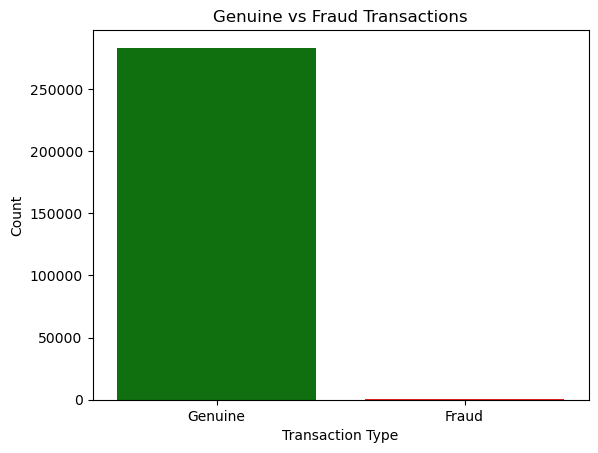

In [30]:
sns.barplot(x=['Genuine', 'Fraud'],
            y=[genuine_transactions, fraud_transactions],
            palette=['green', 'red'],hue=['Genuine', 'Fraud'],legend=False)
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.title("Genuine vs Fraud Transactions")
plt.show()

In [31]:
#doing standardization as amount is in diff format

In [32]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [33]:
df['Normalized_Amount']=scaler.fit_transform(df['Amount'].values.reshape(-1,1)) #reshape (-1,1) converts the 1D arr of Amount in 2D as it is required 2D

In [34]:
df  #as u can see normalized amount column is added which is scaled so now we dont need amount column 

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Normalized_Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0.244200
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,-0.342584
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,1.158900
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0.139886
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,-0.073813
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283721,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0,-0.350252
283722,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0,-0.254325
283723,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0,-0.082239
283724,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0,-0.313391


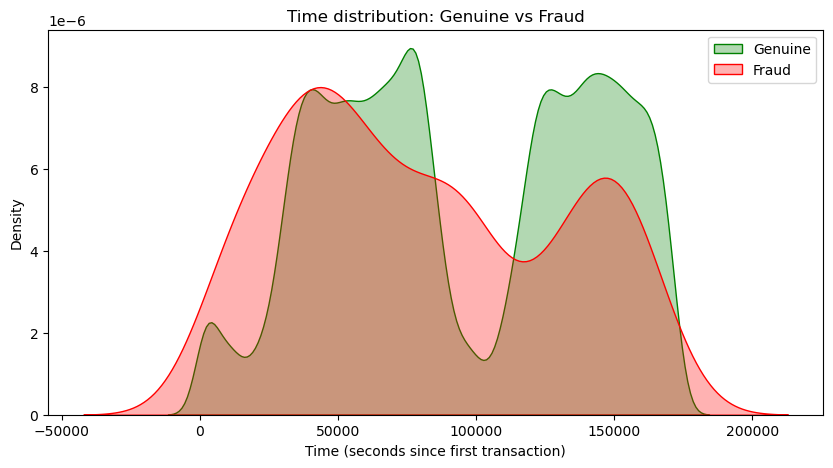

In [35]:
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df[df['Class'] == 0], x='Time', color='green', fill=True, alpha=0.3, label='Genuine')
sns.kdeplot(data=df[df['Class'] == 1], x='Time', color='red', fill=True, alpha=0.3, label='Fraud')
plt.title('Time distribution: Genuine vs Fraud')
plt.xlabel('Time (seconds since first transaction)')
plt.ylabel('Density')
plt.legend()
plt.show()

In [36]:
!pip install imbalanced-learn

We remove Time because it is only the number of seconds since the first transaction in this dataset, not a real clock time, so it has no meaning for new transactions in the real world.

It also shows very low correlation with Class, and the fraud and genuine Time distributions largely overlap, so it can't separate fraud from genuine.

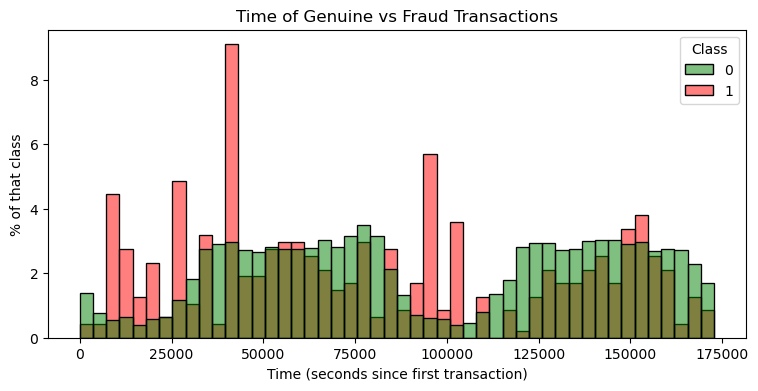

In [37]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x='Time', hue='Class', bins=48,
             stat='percent', common_norm=False,
             palette={0: 'green', 1: 'red'})
plt.title('Time of Genuine vs Fraud Transactions')
plt.xlabel('Time (seconds since first transaction)')
plt.ylabel('% of that class')
plt.show()

In [38]:
x=df.drop(columns=['Time','Amount','Class']) #Fraud occurs throughout the entire time range with no clear pattern, so Time was removed
y=df['Class']

In [39]:
x

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Normalized_Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.244200
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.342584
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.158900
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.139886
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,-0.073813
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283721,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,-0.350252
283722,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,-0.254325
283723,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,-0.082239
283724,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,-0.313391


In [40]:
y

0         0
1         0
2         0
3         0
4         0
         ..
283721    0
283722    0
283723    0
283724    0
283725    0
Name: Class, Length: 283726, dtype: int64

In [41]:
from sklearn.model_selection import train_test_split

In [42]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [43]:
from imblearn.over_sampling import SMOTE #using smote to balance the data 

In [44]:
smote=SMOTE(random_state=24)
x_train_sm,y_train_sm=smote.fit_resample(x_train,y_train)

C:\Users\SAMARTH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\SAMARTH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\SAMARTH\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SAMARTH\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\SAMARTH\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

In [45]:
print("Before SMOTE:") #now our data is perfectly balanced
print(y_train.value_counts())

print("After SMOTE:")
print(y_train_sm.value_counts())
print(x_train_sm.shape)

Before SMOTE:
Class
0    226597
1       383
Name: count, dtype: int64
After SMOTE:
Class
0    226597
1    226597
Name: count, dtype: int64
(453194, 29)


## Model Building

In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [47]:
model1=DecisionTreeClassifier()
model1.fit(x_train_sm,y_train_sm)

DecisionTreeClassifier()

In [48]:
dt_pred=model1.predict(x_test)

In [49]:
dt_accuracy=accuracy_score(y_test,dt_pred)*100
print(f"Decision Tree Accuracy is {dt_accuracy}")

Decision Tree Accuracy is 99.75504881401332


In [50]:
print(classification_report(y_test, dt_pred))
#precision meaning for eg:
# model says 10 transaction are fraud
#but actually data 9 are fraud
# 9/10 = 0.90
# high precision = model give accurate fraud answers

# recall : how many real frauds data the model caught
# there are 10 real frauds
# model caught only 6
# 6/10 : 0.60
# high recall : catches more fraud

#F1 score: is precsion+recall

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56656
           1       0.36      0.73      0.49        90

    accuracy                           1.00     56746
   macro avg       0.68      0.87      0.74     56746
weighted avg       1.00      1.00      1.00     56746



In [51]:
model2=RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
model2.fit(x_train_sm,y_train_sm)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [52]:
rf_pred=model2.predict(x_test)

In [53]:
rf_accuracy=accuracy_score(rf_pred,y_test)*100
print(f"Random Forest Accuracy is {rf_accuracy}")

Random Forest Accuracy is 99.95594403129736


In [54]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56656
           1       0.92      0.79      0.85        90

    accuracy                           1.00     56746
   macro avg       0.96      0.89      0.93     56746
weighted avg       1.00      1.00      1.00     56746



In [55]:
from sklearn.linear_model import LogisticRegression

In [56]:
model3=LogisticRegression()
model3.fit(x_train_sm,y_train_sm)

LogisticRegression()

In [57]:
lr_pred=model3.predict(x_test)

In [58]:
lr_accuracy=accuracy_score(lr_pred,y_test)*100
print(f"Logistic Regression Accuracy is {lr_accuracy}")

Logistic Regression Accuracy is 97.56458605011808


In [59]:
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56656
           1       0.06      0.89      0.10        90

    accuracy                           0.98     56746
   macro avg       0.53      0.93      0.55     56746
weighted avg       1.00      0.98      0.99     56746



In [60]:
from sklearn.svm import SVC

In [61]:
model4=SVC(kernel='rbf') #default kernal

In [62]:
model4.fit(x_train_sm,y_train_sm)

SVC()

In [63]:
svm_pred=model4.predict(x_test)

In [64]:
svm_accuracy=accuracy_score(svm_pred,y_test)*100
print(f" SVM model Accuracy is {lr_accuracy}")

 SVM model Accuracy is 97.56458605011808


In [65]:
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56656
           1       0.07      0.86      0.13        90

    accuracy                           0.98     56746
   macro avg       0.54      0.92      0.56     56746
weighted avg       1.00      0.98      0.99     56746



In [67]:
!pip install xgboost

In [68]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

model5 = XGBClassifier(n_estimators=100, n_jobs=-1, random_state=42, eval_metric='logloss')
model5.fit(x_train_sm, y_train_sm)
xgb_pred = model5.predict(x_test)

xgb_accuracy = accuracy_score(y_test, xgb_pred) * 100
print(f"XGBoost Accuracy is {xgb_accuracy:.2f}")
print(classification_report(y_test, xgb_pred))

XGBoost Accuracy is 99.93
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56656
           1       0.79      0.78      0.78        90

    accuracy                           1.00     56746
   macro avg       0.89      0.89      0.89     56746
weighted avg       1.00      1.00      1.00     56746



XGBoost achieved a fraud F1 of 0.78 with precision 0.79 and recall 0.78. Random Forest performed best overall (F1 0.85), so it was selected as the final model

_This project built a credit card fraud detection system on a highly imbalanced dataset, where only about 0.17% of transactions are fraud. After scaling Amount and removing Time, SMOTE was applied to the training data only, and the models were evaluated on an untouched test set using fraud precision, recall, and F1 instead of accuracy._

Random Forest performed best, with precision 0.92, recall 0.79, and F1 0.85. XGBoost was close behind (F1 0.78). The Decision Tree (F1 0.48) and Logistic Regression (F1 0.10) were weaker, mainly because of many false alarms. Random Forest was therefore selected as the final model.

Limitations: the test set had only 90 fraud cases, so scores can shift with a different split. Scaling was done before the split, and results are limited to the models tested.

Future work: hyperparameter tuning, trying LightGBM, threshold tuning